In [1]:
import cantera as ct
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

In [4]:
def solve_free_flame(phi, T_u=300.0, p=101325.0,
                     transport="mixture-averaged",
                     fuel="H2", oxidizer="O2:1, N2:3.76",
                     mechanism="h2o2.yaml", width=0.03):
    """
    Solve a freely propagating premixed flame.

    Parameters
    ----------
    phi : float
        Equivalence ratio.
    T_u : float
        Unburned mixture temperature in K.
    p : float
        Pressure in Pa.
    transport : {"mixture-averaged", "unity-Lewis-number"}
        Transport model.
    fuel : str
        Fuel species name.
    oxidizer : str
        Oxidizer composition string.
    mechanism : str
        Cantera mechanism file.
    width : float
        Domain width in m.

    Returns
    -------
    cantera.FreeFlame
        Solved flame object.
    """
    gas = ct.Solution(mechanism, transport_model=transport)
    gas.set_equivalence_ratio(phi, fuel, oxidizer)
    gas.TP = T_u, p

    flame = ct.FreeFlame(gas, width=width)
    flame.set_refine_criteria(ratio=2.0, slope=0.005, curve=0.01)
    flame.set_max_grid_points(flame.flame, 10000)
    flame.solve(loglevel=0, auto=True)

    return flame


In [7]:
phi = 1.0

flame = solve_free_flame(phi)

flame_df = flame.to_pandas()

flame_df.head()

,grid,velocity,T,density,X_H2,X_H,X_O,X_O2,X_OH,X_H2O,X_HO2,X_H2O2,X_AR,X_N2
0,0.000,2.330984,300.0,0.849472,0.295858,3.064913e-14,5.554197e-15,0.147929,1.745315e-14,3.747841e-17,0.0,6.186411e-15,0.0,0.556213
1,0.006,2.330984,300.0,0.849472,0.295858,3.784875e-18,4.785144e-15,0.147929,1.555291e-16,1.812253e-14,0.0,6.184487e-15,0.0,0.556213
2,0.009,2.330984,300.0,0.849472,0.295858,1.308085e-19,4.429265e-15,0.147929,8.640028e-18,1.862558e-14,0.0,6.183497e-15,0.0,0.556213
3,0.012,2.330984,300.0,0.849472,0.295858,1.002911e-19,4.099854e-15,0.147929,5.702416e-18,1.895799e-14,0.0,6.182484e-15,0.0,0.556213
4,0.015,2.330984,300.0,0.849472,0.295858,9.248441e-20,3.794904e-15,0.147929,5.239343e-18,1.926344e-14,0.0,6.181450e-15,0.0,0.556213


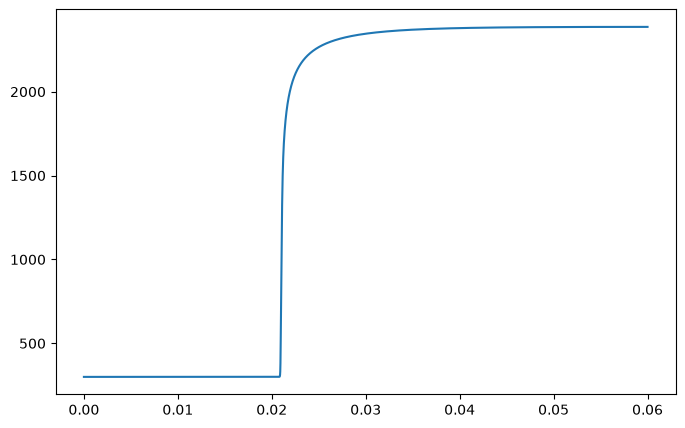

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(flame_df["grid"], flame_df["T"])

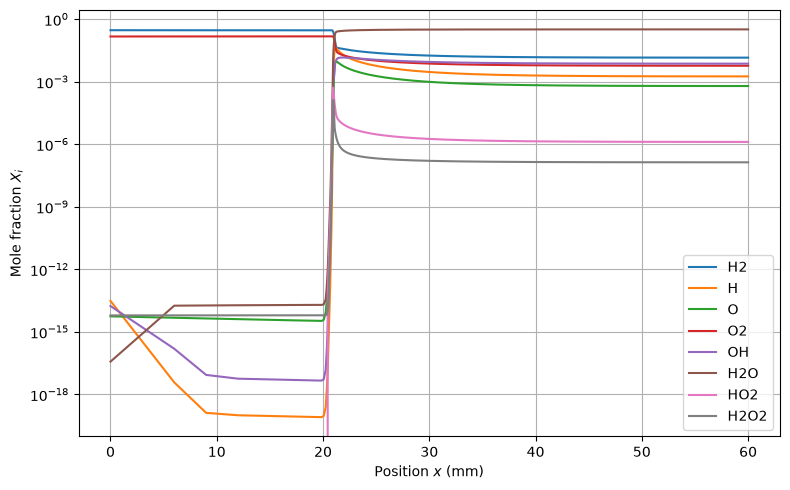

In [11]:
species = ["H2", "H", "O", "O2", "OH", "H2O", "HO2", "H2O2"]

plt.figure(figsize=(8, 5))
for sp in species:
    plt.plot(flame_df["grid"] * 1e3, flame_df[f"X_{sp}"], label=sp)

plt.yscale("log")
plt.xlabel("Position $x$ (mm)")
plt.ylabel("Mole fraction $X_i$")
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()


In [12]:
def flame_speed(flame):
    """
    Return the laminar flame speed from a solved FreeFlame.

    Returns
    -------
    float
        S_L in m/s.
    """
    return float(flame.velocity[0])

In [17]:
vel = flame_speed(flame)

print(f"Laminar flame speed = {vel:.2f} m/s")

Laminar flame speed = 2.33 m/s


In [37]:
def flame_thickness(flame):
    """
    Return the thermal flame thickness.

    Defined as (T_b - T_u) / max(dT/dx).

    Returns
    -------
    float
        delta_L in m.
    """
    T    = flame.T
    x    = flame.grid
    dTdx = np.gradient(T, x)
    return float((T[-1] - T[0]) / np.max(dTdx))

In [38]:
flame_d = flame_thickness(flame)

print(f"Thermal flame thickness = {flame_d*1e3:.2f} mm")

Thermal flame thickness = 0.33 mm


# step 2 - plot flame structure

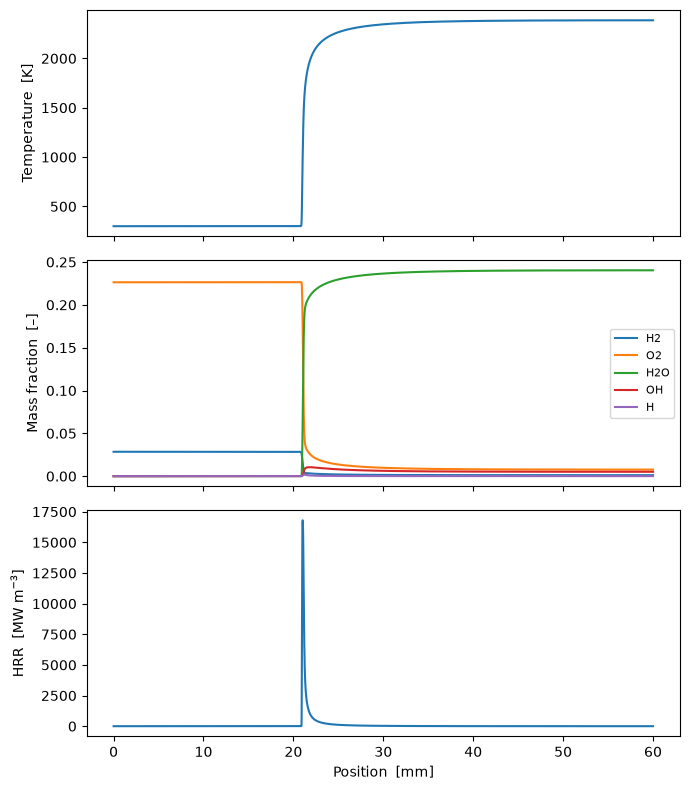

In [20]:
flame = solve_free_flame(phi=1.0)
gas   = flame.gas

x_mm  = flame.grid * 1e3   # m → mm

fig, axes = plt.subplots(3, 1, figsize=(7, 8), sharex=True)

# Panel 1: Temperature
axes[0].plot(x_mm, flame.T)
axes[0].set_ylabel("Temperature  [K]")

# Panel 2: Species
for sp in ["H2", "O2", "H2O", "OH", "H"]:
    axes[1].plot(x_mm, flame.Y[gas.species_index(sp)], label=sp)
axes[1].set_ylabel("Mass fraction  [–]")
axes[1].legend(fontsize=8)

# Panel 3: Heat release rate
axes[2].plot(x_mm, flame.heat_release_rate / 1e6)
axes[2].set_ylabel("HRR  [MW m$^{-3}$]")
axes[2].set_xlabel("Position  [mm]")

fig.tight_layout()

# Task 2 - Equilibrium Composition Check

In [21]:
# Equilibrium reference
gas_eq = ct.Solution("h2o2.yaml")
gas_eq.set_equivalence_ratio(1.0, "H2", "O2:1, N2:3.76")
gas_eq.TP = 300, ct.one_atm
gas_eq.equilibrate("HP")

# Flame burned-gas state
flame = solve_free_flame(phi=1.0)
T_b   = flame.T[-1]

print(f"T_eq  = {gas_eq.T:.1f} K")
print(f"T_b   = {T_b:.1f} K")
print(f"Error = {abs(T_b - gas_eq.T) / gas_eq.T * 100:.2f} %")

T_eq  = 2387.6 K
T_b   = 2386.1 K
Error = 0.06 %


H2O  flame = 3.2404e-01   eq = 3.2437e-01   rel. diff = 0.10 %
H2   flame = 1.4300e-02   eq = 1.4565e-02   rel. diff = 1.82 %
O2   flame = 5.8410e-03   eq = 5.6094e-03   rel. diff = 4.13 %
OH   flame = 7.3552e-03   eq = 7.2848e-03   rel. diff = 0.97 %


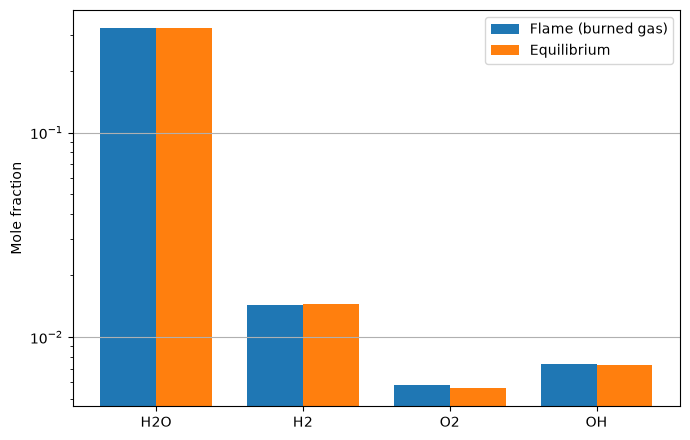

In [22]:
# Major species: last flame grid point vs equilibrium
species = ["H2O", "H2", "O2", "OH"]
idx     = [gas_eq.species_index(sp) for sp in species]
X_flame = flame.X[idx, -1]          # flame.X has shape (n_species, n_points)
X_eq    = gas_eq.X[idx]

for sp, xf, xe in zip(species, X_flame, X_eq):
    print(f"{sp:4s} flame = {xf:.4e}   eq = {xe:.4e}   rel. diff = {abs(xf - xe) / xe * 100:.2f} %")

pos, w = np.arange(len(species)), 0.38
plt.figure(figsize=(7, 4.5))
plt.bar(pos - w/2, X_flame, w, label="Flame (burned gas)")
plt.bar(pos + w/2, X_eq,    w, label="Equilibrium")
plt.xticks(pos, species)
plt.yscale("log")
plt.ylabel("Mole fraction")
plt.grid(axis="y")
plt.legend()
plt.tight_layout()
plt.show()

# Task 3 - transport Model Comparison

In [40]:
flame_ma = solve_free_flame(phi=1.0, transport="mixture-averaged")
flame_le = solve_free_flame(phi=1.0, transport="unity-Lewis-number")

flame_thickness_ma = flame_thickness(flame_ma)
flame_thickness_le = flame_thickness(flame_le)
flame_speed_ma     = flame_speed(flame_ma)
flame_speed_le     = flame_speed(flame_le)

print(f"MixAvg: S_L = {flame_speed_ma*100:.2f} cm/s, delta_L = {flame_thickness_ma*1e3:.3f} mm")
print(f"Le = 1: S_L = {flame_speed_le*100:.2f} cm/s, delta_L = {flame_thickness_le*1e3:.3f} mm")


MixAvg: S_L = 233.10 cm/s, delta_L = 0.329 mm
Le = 1: S_L = 163.95 cm/s, delta_L = 0.293 mm


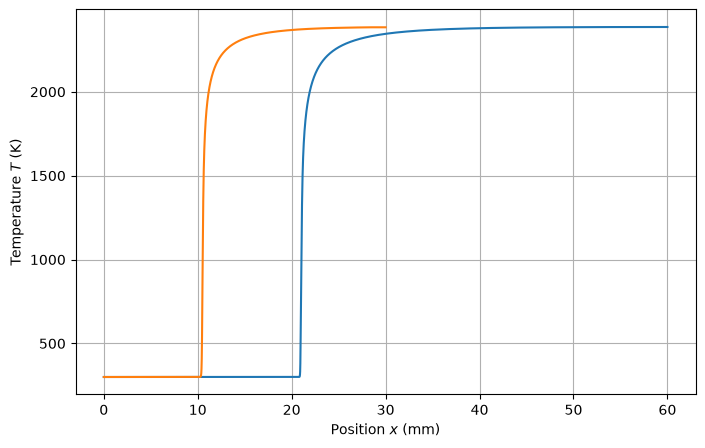

In [41]:
plt.figure(figsize=(8, 5))

plt.plot(flame_ma.grid * 1e3, flame_ma.T, label="MixAvg")
plt.plot(flame_le.grid * 1e3, flame_le.T, label="Le = 1")
plt.xlabel("Position $x$ (mm)")
plt.ylabel("Temperature $T$ (K)")
plt.grid()

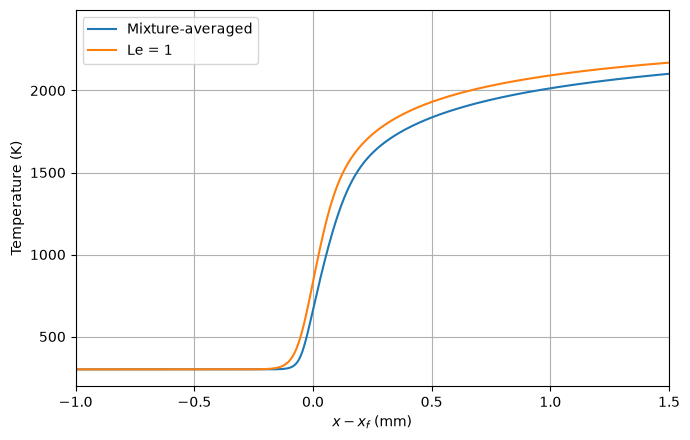

In [42]:
x_ma = flame_ma.grid - flame_ma.grid[np.argmax(np.gradient(flame_ma.T, flame_ma.grid))]
x_le = flame_le.grid - flame_le.grid[np.argmax(np.gradient(flame_le.T, flame_le.grid))]

plt.figure(figsize=(7, 4.5))
plt.plot(x_ma * 1e3, flame_ma.T, label="Mixture-averaged")
plt.plot(x_le * 1e3, flame_le.T, label="Le = 1")
plt.xlim(-1, 1.5)
plt.xlabel("$x - x_f$ (mm)")
plt.ylabel("Temperature (K)")
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()


In [44]:
gas_Z = ct.Solution("h2o2.yaml")
gas_Z.set_equivalence_ratio(1.0, "H2", "O2:1, N2:3.76")
Z_st = gas_Z.mixture_fraction("H2", "O2:1, N2:3.76")

def mixture_fraction(flame, fuel="H2", oxidizer="O2:1, N2:3.76"):
    Z = np.empty(len(flame.grid))
    for i, Y in enumerate(flame.Y.T):          # flame.Y has shape (n_species, n_points)
        gas_Z.Y = Y
        Z[i] = gas_Z.mixture_fraction(fuel, oxidizer)
    return Z

Z_ma = mixture_fraction(flame_ma)
Z_le = mixture_fraction(flame_le)


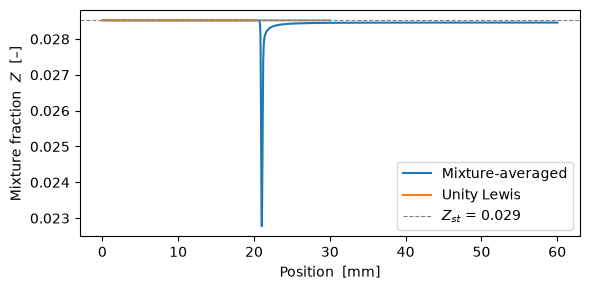

In [45]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(flame_ma.grid * 1e3, Z_ma, label="Mixture-averaged")
ax.plot(flame_le.grid * 1e3, Z_le, label="Unity Lewis")
ax.axhline(Z_st, ls="--", color="gray", lw=0.8, label=f"$Z_{{st}}$ = {Z_st:.3f}")
ax.set_xlabel("Position  [mm]")
ax.set_ylabel("Mixture fraction  $Z$  [–]")
ax.legend()
fig.tight_layout()


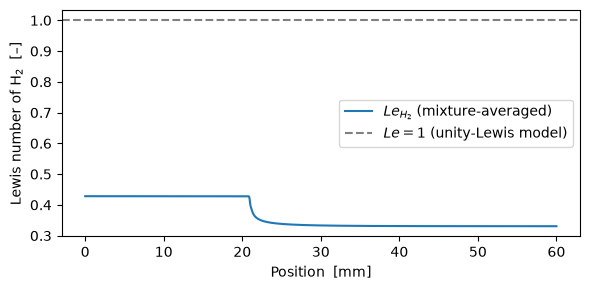

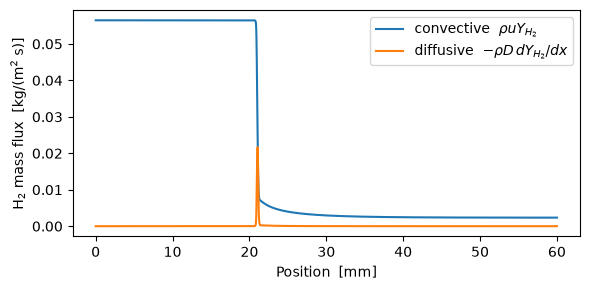

In [47]:
k = flame_ma.gas.species_index("H2")
x = flame_ma.grid * 1e3

# 2. Lewis number of H2 through the flame
alpha = flame_ma.thermal_conductivity / (flame_ma.density * flame_ma.cp_mass)
Le_H2 = alpha / flame_ma.mix_diff_coeffs[k]

plt.figure(figsize=(6, 3))
plt.plot(x, Le_H2, label="$Le_{H_2}$ (mixture-averaged)")
plt.axhline(1, ls="--", color="gray", label="$Le = 1$ (unity-Lewis model)")
plt.xlabel("Position  [mm]")
plt.ylabel("Lewis number of H$_2$  [–]")
plt.legend()
plt.tight_layout()

# 3. H2 mass flux: convective vs diffusive
Y = flame_ma.Y[k]
J_conv = flame_ma.density * flame_ma.velocity * Y
J_diff = -flame_ma.density * flame_ma.mix_diff_coeffs[k] * np.gradient(Y, flame_ma.grid)

plt.figure(figsize=(6, 3))
plt.plot(x, J_conv, label=r"convective  $\rho u Y_{H_2}$")
plt.plot(x, J_diff, label=r"diffusive  $-\rho D\,dY_{H_2}/dx$")
plt.xlabel("Position  [mm]")
plt.ylabel("H$_2$ mass flux  [kg/(m$^2$ s)]")
plt.legend()
plt.tight_layout()


# Task 4 - $S_L(\phi)$ and $\delta_L(\phi)$ Curves

In [49]:
def flame_speed_sweep(phi_range, T_u=300.0, p=101325.0,
                      transport="mixture-averaged",
                      fuel="H2", oxidizer="O2:1, N2:3.76",
                      mechanism="h2o2.yaml"):
    """
    Compute S_L over a range of equivalence ratios.

    Returns
    -------
    numpy.ndarray
        S_L in m/s, same shape as phi_range.
    """
    phi_range = np.asarray(phi_range, dtype=float)
    S_L = np.empty_like(phi_range)

    for i, phi in np.ndenumerate(phi_range):
        flame = solve_free_flame(phi, T_u, p, transport, fuel, oxidizer, mechanism)
        S_L[i] = flame_speed(flame)

    return S_L

In [50]:
def flame_thickness_sweep(phi_range, T_u=300.0, p=101325.0,
                           transport="mixture-averaged",
                           fuel="H2", oxidizer="O2:1, N2:3.76",
                           mechanism="h2o2.yaml"):
    """
    Compute delta_L over a range of equivalence ratios.

    Returns
    -------
    numpy.ndarray
        delta_L in m, same shape as phi_range.
    """
    
    
    phi_range = np.asarray(phi_range, dtype=float)
    delta_L = np.empty_like(phi_range)

    for i, phi in np.ndenumerate(phi_range):
        flame = solve_free_flame(phi, T_u, p, transport, fuel, oxidizer, mechanism)
        
        T = flame.T
        x = flame.grid
        dTdx = np.gradient(T, x)
        delta_L[i] = float((T[-1] - T[0]) / np.max(dTdx))

    return delta_L

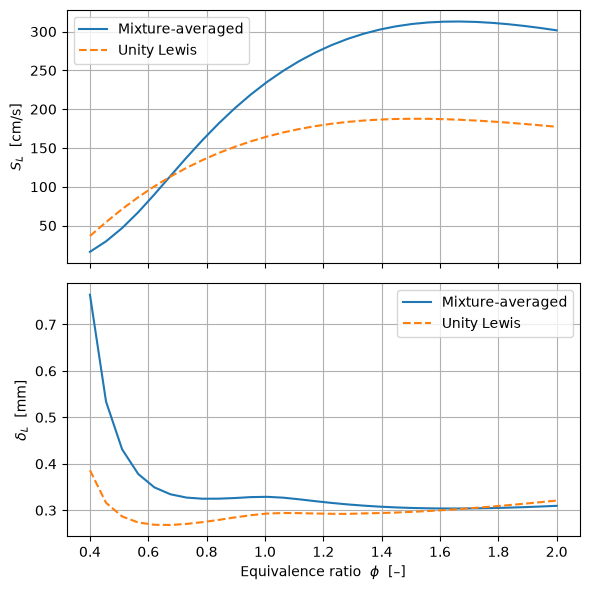

In [56]:
phi_range = np.linspace(0.4, 2.0, 30)

S_L_ma = flame_speed_sweep(phi_range, transport="mixture-averaged")
S_L_le = flame_speed_sweep(phi_range, transport="unity-Lewis-number")
d_ma   = flame_thickness_sweep(phi_range, transport="mixture-averaged")
d_le   = flame_thickness_sweep(phi_range, transport="unity-Lewis-number")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6), sharex=True)

ax1.plot(phi_range, S_L_ma * 100, "-",  color="C0", label="Mixture-averaged")
ax1.plot(phi_range, S_L_le * 100, "--", color="C1", label="Unity Lewis")
ax1.set_ylabel("$S_L$  [cm/s]")
ax1.legend()
ax1.grid()

ax2.plot(phi_range, d_ma * 1e3, "-",  color="C0", label="Mixture-averaged")
ax2.plot(phi_range, d_le * 1e3, "--", color="C1", label="Unity Lewis")
ax2.set_xlabel("Equivalence ratio  $\\phi$  [–]")
ax2.set_ylabel("$\\delta_L$  [mm]")
ax2.legend()
ax2.grid()

fig.tight_layout()
plt.show()


# Task 5 - Pressure and Preheat Variations

In [58]:
ps  = np.linspace(1, 10, 20)       # pressure [atm]
phi = 1.0
S_L_ma, S_L_le, d_ma, d_le = (np.empty_like(ps) for _ in range(4))

for i, p in enumerate(ps):
    p_pa = p * ct.one_atm
    S_L_ma[i] = flame_speed_sweep([phi], transport="mixture-averaged",   p=p_pa)[0]
    S_L_le[i] = flame_speed_sweep([phi], transport="unity-Lewis-number", p=p_pa)[0]
    d_ma[i]   = flame_thickness_sweep([phi], transport="mixture-averaged",   p=p_pa)[0]
    d_le[i]   = flame_thickness_sweep([phi], transport="unity-Lewis-number", p=p_pa)[0]

In [63]:
n, ln_C = np.polyfit(np.log(ps), np.log(S_L_ma), 1)
C = np.exp(ln_C)
print(f"S_L = {C:.3f} * p^{n:.3f}")

S_L = 2.599 * p^-0.209


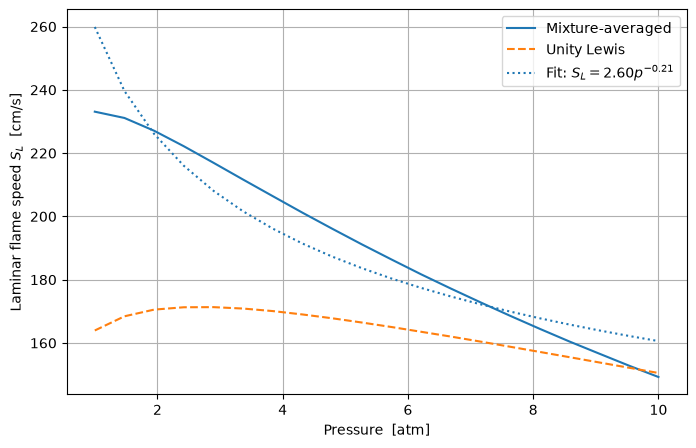

In [65]:
plt.figure(figsize=(8, 5))
plt.plot(ps, S_L_ma * 100, "-",  color="C0", label="Mixture-averaged")
plt.plot(ps, S_L_le * 100, "--", color="C1", label="Unity Lewis")
plt.plot(ps, C * ps**n * 100, ":", color="C0", label=f"Fit: $S_L = {C:.2f} p^{{{n:.2f}}}$")
plt.xlabel("Pressure  [atm]")
plt.ylabel("Laminar flame speed $S_L$  [cm/s]")
plt.grid()
plt.legend()

In [66]:
n, ln_C = np.polyfit(np.log(ps), np.log(d_ma), 1)
C = np.exp(ln_C)
print(f"$\\delta$ = {C:.3f} * p^{n:.3f}")

$\delta$ = 0.000 * p^-1.130


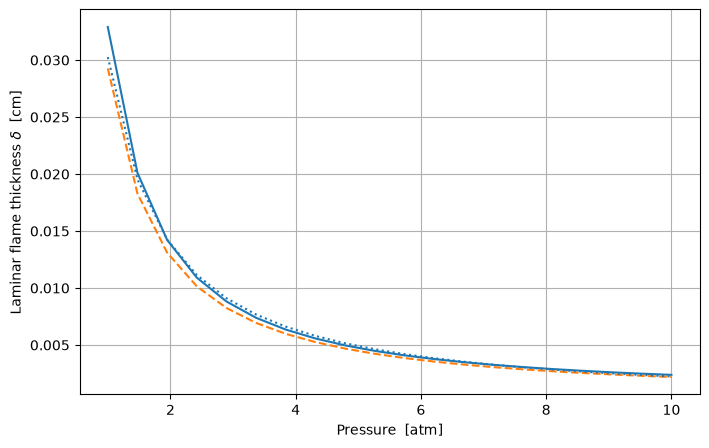

In [67]:
plt.figure(figsize=(8, 5))
plt.plot(ps, d_ma * 100, "-",  color="C0", label="Mixture-averaged")
plt.plot(ps, d_le * 100, "--", color="C1", label="Unity Lewis")
plt.plot(ps, C * ps**n * 100, ":", color="C0", label=f"Fit: $\\delta = {C:.2f} p^{{{n:.2f}}}$")
plt.xlabel("Pressure  [atm]")
plt.ylabel("Laminar flame thickness $\\delta$  [cm]")
plt.grid()

# Preheat Temperautre sweep

In [68]:
Ts  = np.linspace(300, 700, 20)       # pressure [atm]
phi = 1.0
S_L_ma, S_L_le, d_ma, d_le = (np.empty_like(Ts) for _ in range(4))

for i, T in enumerate(Ts):
    S_L_ma[i] = flame_speed_sweep([phi], transport="mixture-averaged",   T_u=T)[0]
    S_L_le[i] = flame_speed_sweep([phi], transport="unity-Lewis-number", T_u=T)[0]
    d_ma[i]   = flame_thickness_sweep([phi], transport="mixture-averaged",   T_u=T)[0]
    d_le[i]   = flame_thickness_sweep([phi], transport="unity-Lewis-number", T_u=T)[0]

In [71]:
n, ln_C = np.polyfit(np.log(Ts), np.log(S_L_ma), 1)
C = np.exp(ln_C)
print(f"S_L = {C:.3f} * T^{n:.3f}")

S_L = 0.000 * T^1.687


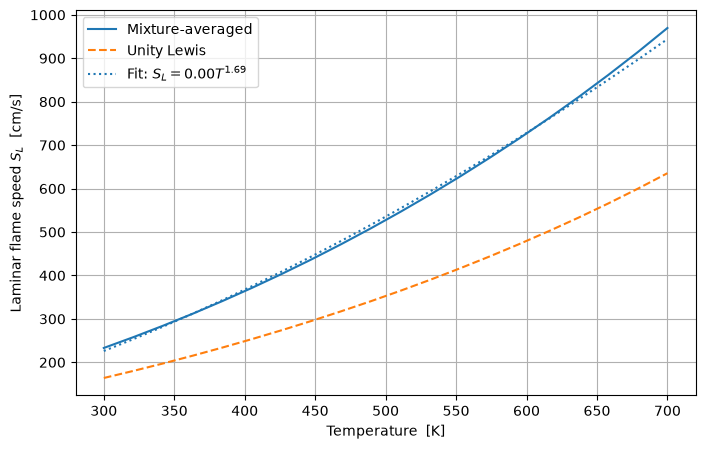

In [72]:
plt.figure(figsize=(8, 5))
plt.plot(Ts, S_L_ma * 100, "-",  color="C0", label="Mixture-averaged")
plt.plot(Ts, S_L_le * 100, "--", color="C1", label="Unity Lewis")
plt.plot(Ts, C * Ts**n * 100, ":", color="C0", label=f"Fit: $S_L = {C:.2f} T^{{{n:.2f}}}$")
plt.xlabel("Temperature  [K]")
plt.ylabel("Laminar flame speed $S_L$  [cm/s]")
plt.grid()
plt.legend()

In [75]:
n, ln_C = np.polyfit(np.log(Ts), np.log(d_ma), 1)
C = np.exp(ln_C)
print(f"\\delta = {C:.3f} * T^{n:.3f}")

\delta = 0.000 * T^0.430


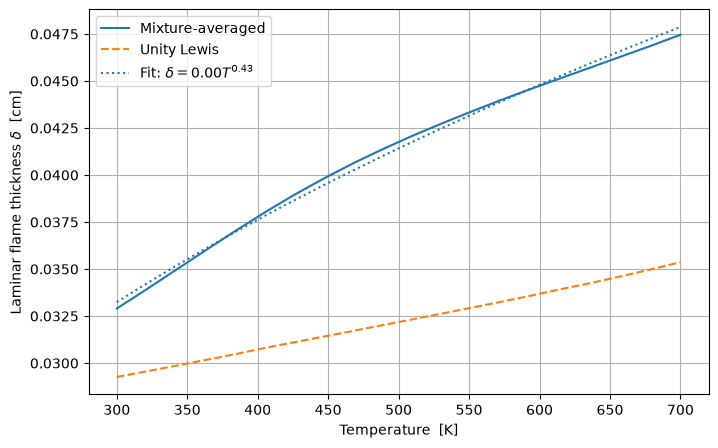

In [76]:
plt.figure(figsize=(8, 5))
plt.plot(Ts, d_ma * 100, "-",  color="C0", label="Mixture-averaged")
plt.plot(Ts, d_le * 100, "--", color="C1", label="Unity Lewis")
plt.plot(Ts, C * Ts**n * 100, ":", color="C0", label=f"Fit: $\\delta = {C:.2f} T^{{{n:.2f}}}$")
plt.xlabel("Temperature  [K]")
plt.ylabel("Laminar flame thickness $\\delta$  [cm]")
plt.grid()
plt.legend()